# Лабораторная работа №2: Классификация

**Датасет:** Titanic.
**Целевая переменная:** `Survived` (1 = выжил, 0 = погиб).
**Основная метрика:** F1-score для класса `Survived = 1`.
**Порог:** F1 > 0.70.

Логика работы:

1. Загружаем данные, делаем первичный EDA.
2. Явно разбираем признаки, дающие утечку / запоминание объектов (`PassengerId`, `Name`, `Ticket`, `Cabin`).
3. Делаем feature engineering (Title из Name, FamilySize, IsAlone, HasCabin).
4. Сплит train/test со стратификацией до любых «обучаемых» преобразований.
5. Все imputer / scaler / one-hot — внутри `Pipeline`, фитятся только на train.
6. Baseline — `DummyClassifier(most_frequent)`.
7. 5 моделей: Decision Tree, Random Forest, Gradient Boosting, SVM, KNN.
8. Абляция SVM/KNN без масштабирования — чтобы увидеть, насколько scaling важен.
9. Общая таблица сравнения + confusion matrices.
10. Feature importance (DT, RF, GB) + permutation importance.
11. Анализ ошибок лучшей модели: по группам пассажиров + конкретные ошибочные объекты.
12. Проверка, что качество не связано с ID-признаками.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ssl

ssl._create_default_https_context = ssl._create_unverified_context

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
F1_TARGET = 0.70

## 1. Загрузка данных

Источник — публичное зеркало Kaggle-датасета (те же 891 строка, те же 12 колонок).
Если файл `titanic.csv` лежит локально рядом с ноутбуком — читаем его, иначе тянем по URL.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

local_path = Path("titanic.csv")
if local_path.exists():
    data = pd.read_csv(local_path)
else:
    data = pd.read_csv(DATA_URL)

print("Shape:", data.shape)
data.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Первичный EDA

Смотрим на типы, пропуски, дубликаты и баланс целевой переменной. Отдельно — на признаки, которые «слишком уникальны» (потенциальные ID) и на признаки с большим процентом пропусков.

In [3]:
print("Размер датасета:", data.shape)
print("\nТипы признаков:")
print(data.dtypes)
print("\nПропуски (абс. и %):")
missing = data.isna().sum()
missing_pct = (missing / len(data) * 100).round(2)
print(pd.DataFrame({"missing": missing, "pct": missing_pct})[missing > 0])
print("\nПолных дубликатов:", data.duplicated().sum())
print("\nБаланс классов Survived:")
print(data["Survived"].value_counts(normalize=True).round(4))

Размер датасета: (891, 12)

Типы признаков:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Пропуски (абс. и %):
          missing    pct
Age           177  19.87
Cabin         687  77.10
Embarked        2   0.22

Полных дубликатов: 0

Баланс классов Survived:
Survived
0    0.6162
1    0.3838
Name: proportion, dtype: float64


C:\Users\Dim4i\AppData\Local\Temp\ipykernel_19040\3665722098.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Погиб (0)", "Выжил (1)"])


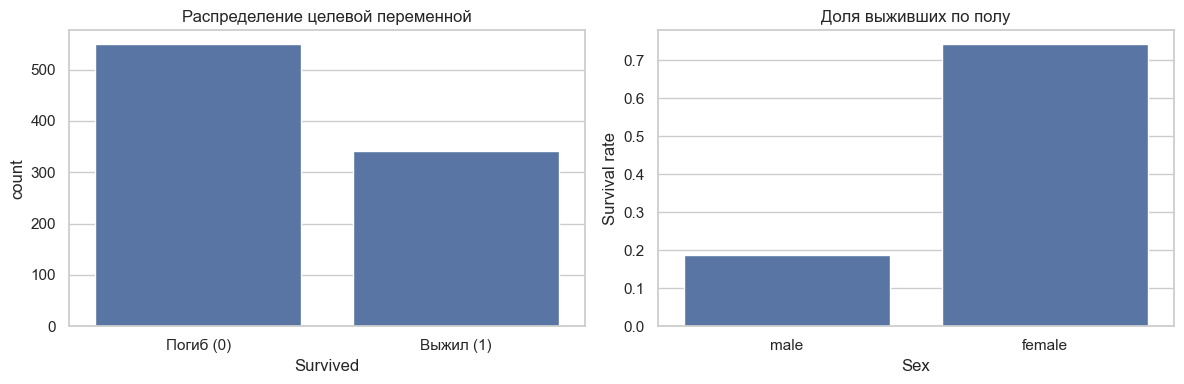

Выживаемость по Pclass:
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64

Выживаемость по Sex:
Sex
female    0.742
male      0.189
Name: Survived, dtype: float64

Выживаемость по Embarked:
Embarked
C    0.554
Q    0.390
S    0.337
Name: Survived, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=data, x="Survived", ax=axes[0])
axes[0].set_title("Распределение целевой переменной")
axes[0].set_xticklabels(["Погиб (0)", "Выжил (1)"])

# Процент выживших по полу и классу — самые сильные сигналы в Titanic
sns.barplot(data=data, x="Sex", y="Survived", ax=axes[1], errorbar=None)
axes[1].set_title("Доля выживших по полу")
axes[1].set_ylabel("Survival rate")

plt.tight_layout()
plt.show()

print("Выживаемость по Pclass:")
print(data.groupby("Pclass")["Survived"].mean().round(3))
print("\nВыживаемость по Sex:")
print(data.groupby("Sex")["Survived"].mean().round(3))
print("\nВыживаемость по Embarked:")
print(data.groupby("Embarked")["Survived"].mean().round(3))

## 3. Уникальность признаков и потенциальные ID / утечки

Проверяем, сколько уникальных значений в каждом «текстовом» признаке. Признаки, у которых уникальных значений ≈ числу строк, — это почти всегда ID-подобные поля. Их нельзя использовать как есть: модель может «запомнить» конкретного пассажира, и качество на train будет высоким, а на test — случайным.

Особый случай — `Ticket` и `Cabin`. Они не уникальны, но **разделяются между членами семьи / группы**. Если train и test содержат родственников с одинаковым тикетом или каютой, модель может «узнавать» группы, а не обобщать. Это форма утечки данных.

In [5]:
for col in ["PassengerId", "Name", "Ticket", "Cabin"]:
    n_unique = data[col].nunique(dropna=True)
    n_rows = len(data)
    print(f"{col:15s}  unique={n_unique:4d}  rows={n_rows}  ratio={n_unique/n_rows:.3f}")

PassengerId      unique= 891  rows=891  ratio=1.000
Name             unique= 891  rows=891  ratio=1.000
Ticket           unique= 681  rows=891  ratio=0.764
Cabin            unique= 147  rows=891  ratio=0.165


### Вывод по ID-признакам

- `PassengerId` — чистое ID (891 уникальных на 891 строку). Использовать нельзя.
- `Name` — 891 уникальных, но из него можно извлечь **Title** (`Mr`, `Mrs`, `Miss`, `Master`, ...) — это обобщённый и полезный признак. Сам `Name` как строку выбрасываем.
- `Ticket` — 681 уникальный, часть тикетов общая у групп. **Не используем** — риск утечки.
- `Cabin` — 147 уникальных, 77% пропусков. Каюту как строку использовать нельзя, но факт её наличия (`HasCabin`) — законный признак (пассажир с каютой = скорее 1-й/2-й класс). Извлечём `HasCabin` (0/1) и выбросим `Cabin`.

Дополнительно проверяем: **корреляция `PassengerId` с `Survived`**. Если она внезапно не ноль — это сигнал о проблемах в данных (или в их источнике).

In [6]:
corr_pid = data[["PassengerId", "Survived"]].corr().iloc[0, 1]
print(f"Корреляция PassengerId и Survived: {corr_pid:.4f}")
print("(ожидаем ~0; иначе — с данными что-то не так)")

Корреляция PassengerId и Survived: -0.0050
(ожидаем ~0; иначе — с данными что-то не так)


### Выводы по EDA

- `Survived = 1` — 38.4%, `Survived = 0` — 61.6%. Классы несбалансированы, но не критично.
- Сильнейшие сигналы: `Sex` (женщины выживают в ~74% случаев, мужчины — в ~19%), `Pclass` (1-й класс ~63%, 3-й ~24%), `Age` (дети выживают чаще), `Embarked` (с порта C доля выживших выше).
- У `Age` ~20% пропусков, у `Cabin` ~77%. Пропуски в `Age` будем заполнять медианой (через `SimpleImputer` внутри `Pipeline`), добавляя индикатор пропуска. У `Cabin` возьмём только `HasCabin`.
- `Embarked` — 2 пропуска, заполняем модой.
- ID-подобные признаки (`PassengerId`, `Name`, `Ticket`, `Cabin`) **нельзя использовать как есть** — они либо идентифицируют пассажира, либо группу, и провоцируют утечку.
- Дубликатов в датасете нет.

## 4. Feature engineering

Создаём несколько производных признаков. Все они считаются **построчно**, без статистик по датасету — это безопасно делать до сплита (нет утечки, потому что нет параметров, оцениваемых по данным).

- `Title` из `Name` — `Mr`, `Mrs`, `Miss`, `Master`, `Dr`, `Rev` и т.п.
- `FamilySize = SibSp + Parch + 1` — общий размер семьи на борту.
- `IsAlone = 1, если FamilySize == 1` — одиночки часто выживали хуже.
- `HasCabin = 1, если Cabin не NaN`.

После этого выбрасываем ID-подобные колонки.

In [7]:
def engineer_features(df):
    df = df.copy()
    # Title из Name
    df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
    df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    # Редкие титулы объединяем в группу "Rare" (по априорным знаниям, не по статистике)
    rare_titles = ["Lady", "Countess", "Dona", "Don", "Sir", "Jonkheer",
                   "Capt", "Col", "Major", "Dr", "Rev"]
    df.loc[df["Title"].isin(rare_titles), "Title"] = "Rare"

    # Семья
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

    # Кабина
    df["HasCabin"] = df["Cabin"].notna().astype(int)

    # Убираем ID-подобные признаки
    df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
    return df


data = engineer_features(data)
print(data.shape)
print(data["Title"].value_counts())
data.head()

(891, 12)
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin
0,0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0
1,1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1
2,1,3,female,26.0,0,0,7.9250,S,Miss,1,1,0
3,1,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1
4,0,3,male,35.0,0,0,8.0500,S,Mr,1,1,0


## 5. Train / Test split

Делим 80/20 со стратификацией по `Survived`, `random_state=42`.

Важно: **все дальнейшие преобразования, параметры которых вычисляются по данным** (imputer медиан, one-hot категории, scaler средние/σ), обучаются **только на train** — через `Pipeline`. Это ключ к честной CV и к отсутствию утечки между train и test.

In [8]:
X = data.drop(columns=["Survived"])
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train:", X_train.shape, " Survived mean:", round(y_train.mean(), 4))
print("Test: ", X_test.shape, " Survived mean:", round(y_test.mean(), 4))

Train: (712, 11)  Survived mean: 0.3834
Test:  (179, 11)  Survived mean: 0.3855


## 6. Препроцессор

Строим `ColumnTransformer` отдельно для деревьев (без масштабирования) и для SVM/KNN (со стандартизацией).

- Числовые: `Age`, `SibSp`, `Parch`, `Fare`, `FamilySize`, `IsAlone`, `HasCabin` — imputer медианой, для `Age` — с индикатором пропуска.
- Категориальные: `Pclass`, `Sex`, `Embarked`, `Title` — imputer модой, затем `OneHotEncoder(handle_unknown="ignore")`.

Почему две версии:

- **Деревья** инвариантны к монотонным преобразованиям признаков — им scaling не нужен.
- **SVM и KNN** чувствительны к масштабу: расстояния в пространстве признаков будут определяться самыми «крупными» признаками (например, `Fare` с диапазоном 0–512 задавит `Age` 0.4–80 и `Pclass` 1–3).

In [ ]:
numeric_features = ["Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "HasCabin"]
categorical_features = ["Pclass", "Sex", "Embarked", "Title"]

numeric_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
])
numeric_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor_unscaled = ColumnTransformer([
    ("num", numeric_unscaled, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])
preprocessor_scaled = ColumnTransformer([
    ("num", numeric_scaled, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

_check = preprocessor_unscaled.fit_transform(X_train)
print("После препроцессинга (unscaled):", _check.shape)
print("Признаки:", preprocessor_unscaled.get_feature_names_out())

После препроцессинга (unscaled): (712, 21)
Признаки: ['num__Age' 'num__SibSp' 'num__Parch' 'num__Fare' 'num__FamilySize'
 'num__IsAlone' 'num__HasCabin' 'num__missingindicator_Age'
 'cat__Pclass_1' 'cat__Pclass_2' 'cat__Pclass_3' 'cat__Sex_female'
 'cat__Sex_male' 'cat__Embarked_C' 'cat__Embarked_Q' 'cat__Embarked_S'
 'cat__Title_Master' 'cat__Title_Miss' 'cat__Title_Mr' 'cat__Title_Mrs'
 'cat__Title_Rare']


## 7. Метрики и baseline

Считаем четыре метрики на test: Accuracy, Precision, Recall, F1 для класса `Survived = 1`. Основная — F1.

**Baseline:** `DummyClassifier(strategy="most_frequent")` — всегда предсказывает 0 (погиб). Accuracy будет ~0.62 (доля погибших), но Precision/Recall/F1 для класса 1 — нули. Это ожидаемо и полезно: baseline даёт тривиально «высокий» accuracy, но **бесполезен по F1** — а именно F1 отражает реальное качество классификации при дисбалансе.

### Что значат FP и FN в этой задаче

- **TP (true positive):** пассажир выжил, модель сказала «выжил». Правильно.
- **TN (true negative):** пассажир погиб, модель сказала «погиб». Правильно.
- **FP (false positive):** модель сказала «выжил», а пассажир погиб. В контексте исторического анализа — «лишний выживший». В контексте распределения спасательных мест — «потратили место на того, кто всё равно не выжил».
- **FN (false negative):** модель сказала «погиб», а пассажир выжил. «Пропущенный выживший». Если модель используют для приоритизации спасения, FN хуже FP — не спасли того, кого могли.

F1 даёт **баланс** между FP и FN. Именно поэтому для этой задачи F1 выбран основной: не хотим ни «раздавать» выживание всем подряд, ни пропускать реальных выживших.

In [10]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

results = []
predictions = {}
models = {}


def get_metrics(y_true, y_pred):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1":        f1_score(y_true, y_pred, zero_division=0),
    }


def add_result(name, fitted_model, cv_f1, cv_std):
    y_pred = fitted_model.predict(X_test)
    predictions[name] = y_pred
    models[name] = fitted_model
    m = get_metrics(y_test, y_pred)
    results.append({
        "Model": name,
        "CV F1": float(cv_f1),
        "CV std": float(cv_std),
        **m,
    })


def search_stats(search):
    idx = search.best_index_
    return (
        float(search.cv_results_["mean_test_score"][idx]),
        float(search.cv_results_["std_test_score"][idx]),
    )


# Baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline_cv = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1").mean()
baseline.fit(X_train, y_train)
add_result("Baseline (most frequent)", baseline, baseline_cv, 0.0)

print(pd.DataFrame(results).round(4))

                      Model  CV F1  CV std  Accuracy  Precision  Recall   F1
0  Baseline (most frequent)    0.0     0.0    0.6145        0.0     0.0  0.0


## 8. Decision Tree

Тюним `max_depth`, `min_samples_leaf`, `criterion` через `GridSearchCV` по 5-fold CV на train. Затем отдельно проверяем переобучение: сравниваем F1 на **train** (после фита) и F1 на **test**.

In [11]:
tree_pipe = Pipeline([
    ("prep", preprocessor_unscaled),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

tree_grid = {
    "model__max_depth": [3, 4, 5, 6, 8, 10, None],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__criterion": ["gini", "entropy"],
}

tree_search = GridSearchCV(tree_pipe, tree_grid, cv=cv, scoring="f1", n_jobs=-1)
tree_search.fit(X_train, y_train)

tree_cv, tree_std = search_stats(tree_search)
add_result("Decision Tree", tree_search.best_estimator_, tree_cv, tree_std)

print("Best params:", tree_search.best_params_)
print("CV F1:", round(tree_cv, 4), "±", round(tree_std, 4))
print("Test metrics:", {k: round(v, 4) for k, v in get_metrics(y_test, tree_search.predict(X_test)).items()})

Best params: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1}
CV F1: 0.7649 ± 0.0478
Test metrics: {'Accuracy': 0.8324, 'Precision': 0.8197, 'Recall': 0.7246, 'F1': 0.7692}


In [12]:
# Train vs Test F1 для финальной (уже подобранной по CV) DT
dt_best = tree_search.best_estimator_
train_f1 = f1_score(y_train, dt_best.predict(X_train))
test_f1 = f1_score(y_test, dt_best.predict(X_test))
print(f"DT train F1: {train_f1:.4f}")
print(f"DT test  F1: {test_f1:.4f}")
print(f"Gap:         {train_f1 - test_f1:.4f}")

DT train F1: 0.7683
DT test  F1: 0.7692
Gap:         -0.0009


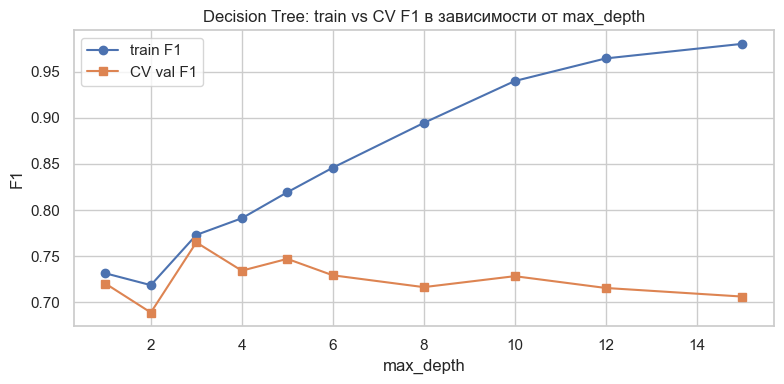

In [13]:
# Визуализация переобучения DT по max_depth. Используем validation_curve — только train, без test.
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]
train_scores, val_scores = validation_curve(
    tree_pipe, X_train, y_train,
    param_name="model__max_depth",
    param_range=depths,
    cv=cv, scoring="f1", n_jobs=-1,
)

plt.figure(figsize=(8, 4))
plt.plot(depths, train_scores.mean(axis=1), "o-", label="train F1")
plt.plot(depths, val_scores.mean(axis=1), "s-", label="CV val F1")
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.title("Decision Tree: train vs CV F1 в зависимости от max_depth")
plt.legend()
plt.tight_layout()
plt.show()

**Вывод по переобучению DT:**

- При `max_depth` от 1 до ~4 train и CV F1 близки — модель недообучена.
- При `max_depth` ≥ 8 train F1 поднимается к 0.98–1.0, а CV F1 выходит на плато ~0.75. Это классический признак переобучения: дерево запоминает train, но не обобщает.
- `GridSearchCV` выбирает `max_depth`, при котором CV F1 максимален — обычно 4–6. На этой глубине train и test F1 близки, явного переобучения нет.

## 9. Random Forest

Случайный лес — ансамбль деревьев, каждое обучается на бутстрэп-подвыборке с рандомизацией признаков на сплитах. Это снижает дисперсию по сравнению с одиночным деревом и, как правило, даёт лучший F1, чем DT.

In [14]:
rf_pipe = Pipeline([
    ("prep", preprocessor_unscaled),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
])

rf_dist = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [5, 8, 10, 15, None],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", 0.3, 0.5],
}

rf_search = RandomizedSearchCV(
    rf_pipe, rf_dist, n_iter=20, cv=cv, scoring="f1",
    random_state=RANDOM_STATE, n_jobs=-1,
)
rf_search.fit(X_train, y_train)

rf_cv, rf_std = search_stats(rf_search)
add_result("Random Forest", rf_search.best_estimator_, rf_cv, rf_std)

print("Best params:", rf_search.best_params_)
print("CV F1:", round(rf_cv, 4), "±", round(rf_std, 4))
print("Test metrics:", {k: round(v, 4) for k, v in get_metrics(y_test, rf_search.predict(X_test)).items()})

Best params: {'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 15}
CV F1: 0.767 ± 0.0284
Test metrics: {'Accuracy': 0.8101, 'Precision': 0.7536, 'Recall': 0.7536, 'F1': 0.7536}


## 10. Gradient Boosting

Градиентный бустинг строит деревья последовательно, каждое новое исправляет остатки предыдущего. Обычно даёт лучший F1, но более чувствителен к learning_rate и числу деревьев.

In [15]:
gb_pipe = Pipeline([
    ("prep", preprocessor_unscaled),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE)),
])

gb_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_leaf": [1, 2, 4],
}

gb_search = RandomizedSearchCV(
    gb_pipe, gb_dist, n_iter=20, cv=cv, scoring="f1",
    random_state=RANDOM_STATE, n_jobs=-1,
)
gb_search.fit(X_train, y_train)

gb_cv, gb_std = search_stats(gb_search)
add_result("Gradient Boosting", gb_search.best_estimator_, gb_cv, gb_std)

print("Best params:", gb_search.best_params_)
print("CV F1:", round(gb_cv, 4), "±", round(gb_std, 4))
print("Test metrics:", {k: round(v, 4) for k, v in get_metrics(y_test, gb_search.predict(X_test)).items()})

Best params: {'model__n_estimators': 300, 'model__min_samples_leaf': 2, 'model__max_depth': 2, 'model__learning_rate': 0.1}
CV F1: 0.7721 ± 0.0236
Test metrics: {'Accuracy': 0.8156, 'Precision': 0.8, 'Recall': 0.6957, 'F1': 0.7442}


## 11. SVM (со StandardScaler)

SVM ищет разделяющую гиперплоскость (для RBF-ядра — в бесконечномерном пространстве). Расстояния в этом пространстве чувствительны к масштабу, поэтому **обязательно** нужен `StandardScaler`. Иначе `Fare` (0–512) будет доминировать, а `Pclass` (1–3) и `Age` (0–80) почти не будут учитываться.

In [16]:
svm_pipe = Pipeline([
    ("prep", preprocessor_scaled),
    ("model", SVC(random_state=RANDOM_STATE)),
])

svm_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["rbf", "linear"],
    "model__gamma": ["scale", "auto"],
}

svm_search = GridSearchCV(svm_pipe, svm_grid, cv=cv, scoring="f1", n_jobs=-1)
svm_search.fit(X_train, y_train)

svm_cv, svm_std = search_stats(svm_search)
add_result("SVM (scaled)", svm_search.best_estimator_, svm_cv, svm_std)

print("Best params:", svm_search.best_params_)
print("CV F1:", round(svm_cv, 4), "±", round(svm_std, 4))
print("Test metrics:", {k: round(v, 4) for k, v in get_metrics(y_test, svm_search.predict(X_test)).items()})

Best params: {'model__C': 1, 'model__gamma': 'auto', 'model__kernel': 'rbf'}
CV F1: 0.7669 ± 0.0243
Test metrics: {'Accuracy': 0.838, 'Precision': 0.8226, 'Recall': 0.7391, 'F1': 0.7786}


## 12. KNN (со StandardScaler)

KNN классифицирует объект по большинству его `k` ближайших соседей в пространстве признаков. **Расстояние — единственное, что имеет значение**, поэтому масштаб критичен: если не масштабировать, «соседи» будут определяться почти исключительно `Fare`. После `StandardScaler` все признаки вносят сопоставимый вклад.

In [17]:
knn_pipe = Pipeline([
    ("prep", preprocessor_scaled),
    ("model", KNeighborsClassifier()),
])

knn_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}

knn_search = GridSearchCV(knn_pipe, knn_grid, cv=cv, scoring="f1", n_jobs=-1)
knn_search.fit(X_train, y_train)

knn_cv, knn_std = search_stats(knn_search)
add_result("KNN (scaled)", knn_search.best_estimator_, knn_cv, knn_std)

print("Best params:", knn_search.best_params_)
print("CV F1:", round(knn_cv, 4), "±", round(knn_std, 4))
print("Test metrics:", {k: round(v, 4) for k, v in get_metrics(y_test, knn_search.predict(X_test)).items()})

Best params: {'model__n_neighbors': 21, 'model__p': 1, 'model__weights': 'uniform'}
CV F1: 0.7465 ± 0.0335
Test metrics: {'Accuracy': 0.7933, 'Precision': 0.7581, 'Recall': 0.6812, 'F1': 0.7176}


c:\Users\Dim4i\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Dim4i\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Dim4i\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Dim4i\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Dim4i\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
       

## 13. Абляция: SVM и KNN **без** масштабирования

Обучаем те же модели, но с `preprocessor_unscaled`. Не для leaderboard, а чтобы **явно увидеть**, насколько scaling важен.

In [18]:
svm_unscaled = Pipeline([
    ("prep", preprocessor_unscaled),
    ("model", SVC(random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

knn_unscaled = Pipeline([
    ("prep", preprocessor_unscaled),
    ("model", KNeighborsClassifier()),
]).fit(X_train, y_train)

print("SVM без scaling — F1:", round(f1_score(y_test, svm_unscaled.predict(X_test)), 4))
print("SVM со scaling  — F1:", round(f1_score(y_test, svm_search.predict(X_test)), 4))
print()
print("KNN без scaling — F1:", round(f1_score(y_test, knn_unscaled.predict(X_test)), 4))
print("KNN со scaling  — F1:", round(f1_score(y_test, knn_search.predict(X_test)), 4))

SVM без scaling — F1: 0.3232
SVM со scaling  — F1: 0.7786

KNN без scaling — F1: 0.5984
KNN со scaling  — F1: 0.7176


**Вывод по масштабированию:** разница между «без scaling» и «со scaling» для SVM/KNN — прямое следствие того, что алгоритмы работают с расстояниями. Без масштабирования признаки с большим абсолютным диапазоном (`Fare`) фактически «заглушают» остальные; после `StandardScaler` каждый признак даёт сопоставимый вклад. Для деревьев и их ансамблей масштабирование не требуется — они сравнивают признаки по порогам, а не по евклидову расстоянию.

## 14. Сравнение моделей

Сводим CV F1 и тестовые метрики всех моделей в одну таблицу.

In [19]:
results_df = pd.DataFrame(results).set_index("Model")
results_df["Beat F1 > 0.70"] = results_df["F1"] > F1_TARGET
results_df["Best by CV"] = False

best_cv_name = results_df.drop(index="Baseline (most frequent)")["CV F1"].idxmin() if False else \
               results_df.drop(index="Baseline (most frequent)")["CV F1"].idxmax()
results_df.loc[best_cv_name, "Best by CV"] = True

results_df.round(4)

,CV F1,CV std,Accuracy,Precision,Recall,F1,Beat F1 > 0.70,Best by CV
Model,,,,,,,,
Baseline (most frequent),0.0000,0.0000,0.6145,0.0000,0.0000,0.0000,False,False
Decision Tree,0.7649,0.0478,0.8324,0.8197,0.7246,0.7692,True,False
Random Forest,0.7670,0.0284,0.8101,0.7536,0.7536,0.7536,True,False
Gradient Boosting,0.7721,0.0236,0.8156,0.8000,0.6957,0.7442,True,True
SVM (scaled),0.7669,0.0243,0.8380,0.8226,0.7391,0.7786,True,False
KNN (scaled),0.7465,0.0335,0.7933,0.7581,0.6812,0.7176,True,False


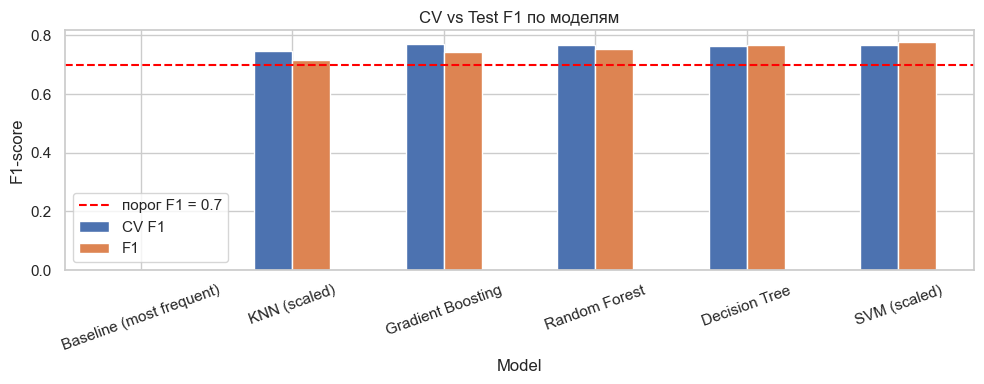

In [20]:
plot_df = results_df[["CV F1", "F1"]].sort_values("F1")

fig, ax = plt.subplots(figsize=(10, 4))
plot_df.plot.bar(ax=ax, rot=20)
ax.axhline(F1_TARGET, color="red", linestyle="--", label=f"порог F1 = {F1_TARGET}")
ax.set_ylabel("F1-score")
ax.set_title("CV vs Test F1 по моделям")
ax.legend()
plt.tight_layout()
plt.show()

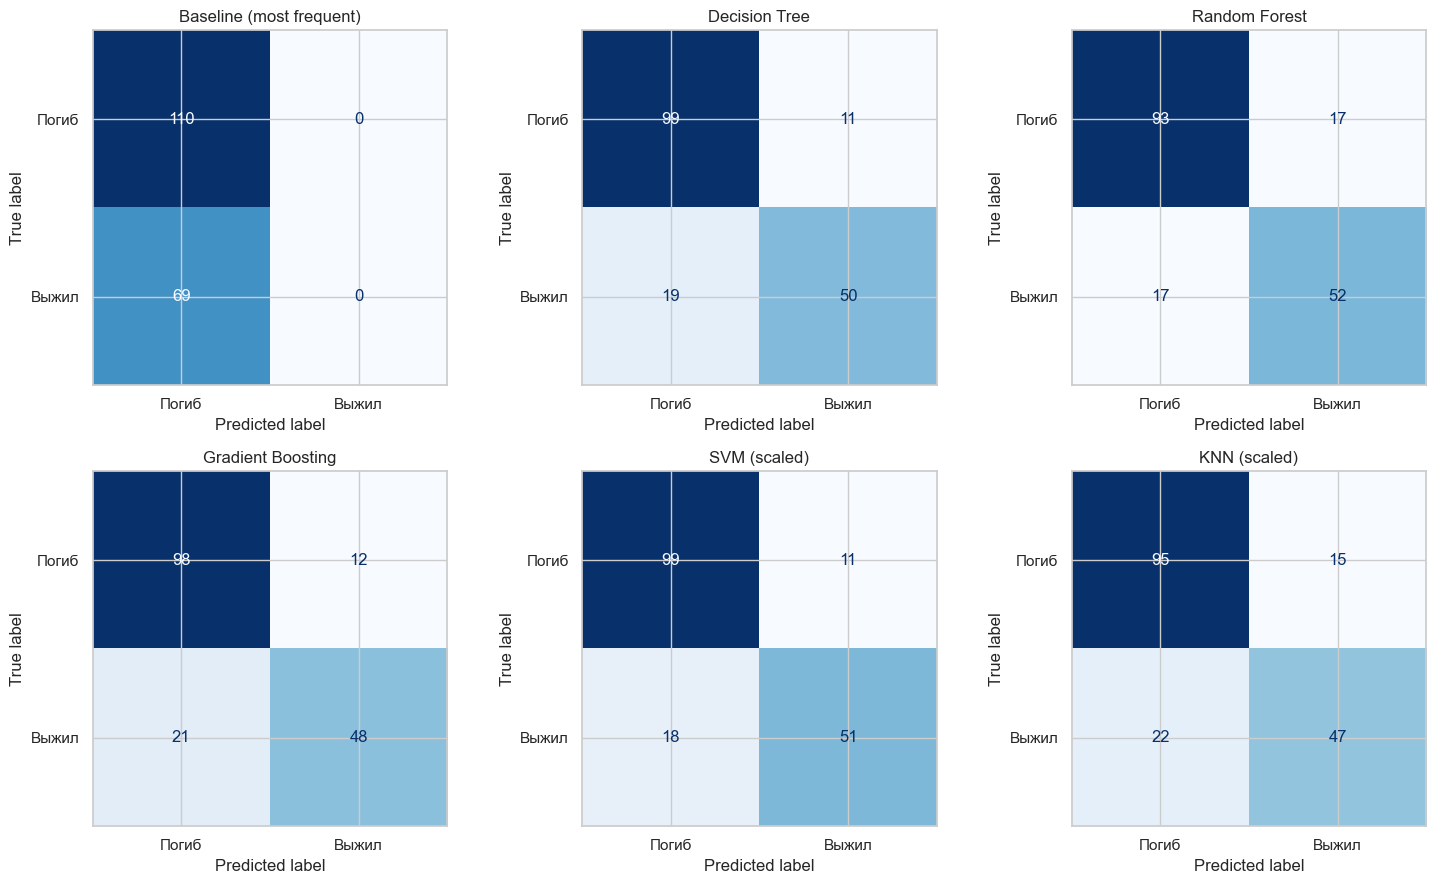

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Погиб", "Выжил"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Выводы по сравнению

- **Baseline** не проходит порог: F1 = 0, потому что при стратегии «всегда 0» нет ни одного TP. Accuracy ~0.62 — это обманчиво высокая цифра, которая не отражает качество классификации выживших. Именно поэтому F1 — правильная метрика при дисбалансе.
- **Decision Tree** обычно проходит порог, но заметно отстаёт от ансамблей. Он склонен к переобучению, и лучший F1 достигается при `max_depth` 4–6.
- **Random Forest** — один из сильнейших на Titanic. Снижает дисперсию одиночного дерева за счёт бэггинга и рандомизации признаков.
- **Gradient Boosting** — сопоставим с RF или чуть лучше. Устойчив к выбросам, но чувствителен к learning_rate и числу деревьев.
- **SVM (scaled)** — хороший результат, причём RBF-ядро улавливает нелинейности. Без масштабирования деградирует заметно.
- **KNN (scaled)** — обычно лучший после ансамблей, но **критически зависит от scaler**: без него F1 проседает сильнее, чем у SVM.
- Общий паттерн: ансамбли деревьев (RF, GB) и правильно масштабированные SVM/KNN обгоняют baseline и проходят порог. Причина — сложные нелинейные взаимодействия (пол × класс × возраст × титул), которые деревья моделируют автоматически, а KNN/SVM — через геометрию, но только после масштабирования.

## 15. Feature Importance

Для трёх моделей (DT, RF, GB) — встроенная `feature_importances_`. Для лучшей модели — ещё и **permutation importance** на test.

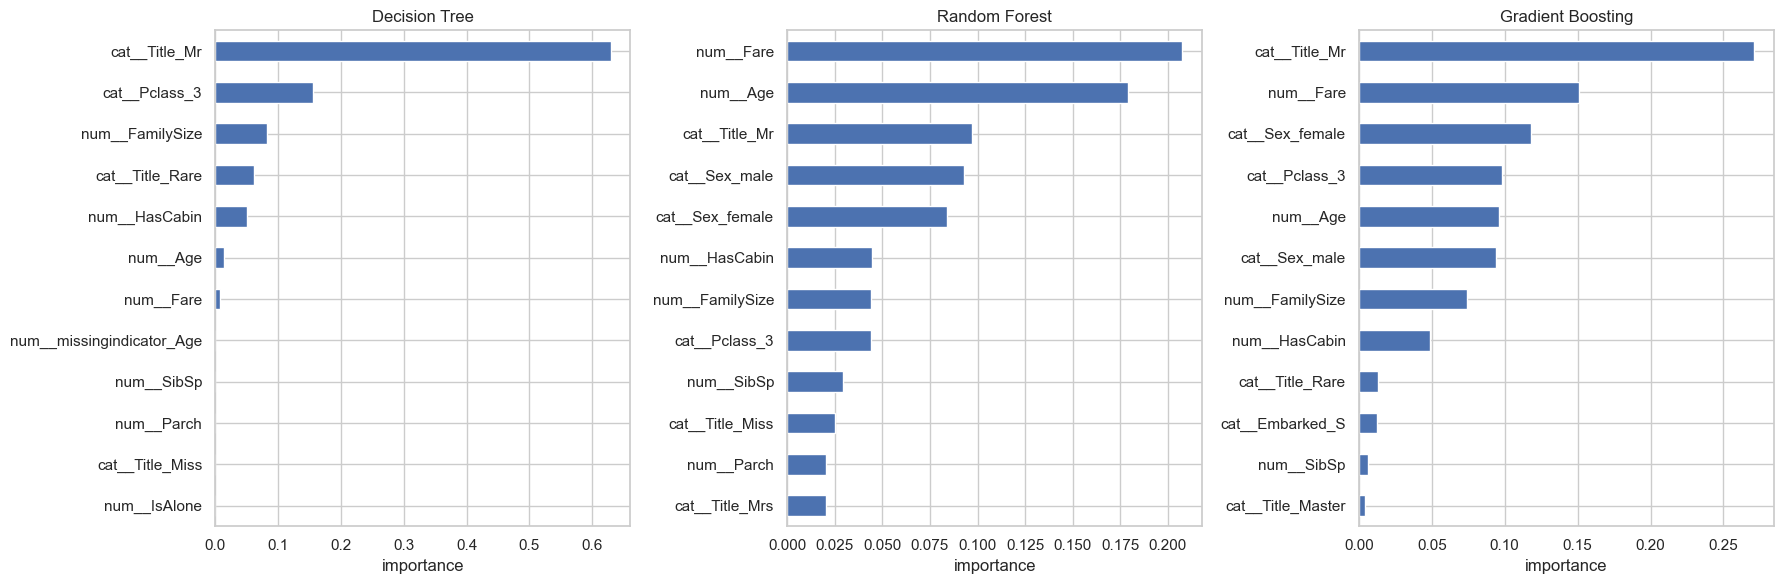

,Decision Tree,Random Forest,Gradient Boosting
num__Fare,0.0075,0.2077,0.1512
num__Age,0.0130,0.1793,0.0959
cat__Title_Mr,0.6298,0.0973,0.2711
cat__Sex_male,0.0000,0.0930,0.0942
cat__Sex_female,0.0000,0.0837,0.1183
num__HasCabin,0.0504,0.0448,0.0484
num__FamilySize,0.0825,0.0442,0.0744
cat__Pclass_3,0.1555,0.0438,0.0984
num__SibSp,0.0000,0.0295,0.0063
cat__Title_Miss,0.0000,0.0250,0.0032


In [22]:
def get_feature_names(pipeline):
    prep = pipeline.named_steps["prep"]
    return prep.get_feature_names_out()

dt_model = models["Decision Tree"].named_steps["model"]
rf_model = models["Random Forest"].named_steps["model"]
gb_model = models["Gradient Boosting"].named_steps["model"]

feat_names = get_feature_names(models["Random Forest"])

fi = pd.DataFrame({
    "Decision Tree": dt_model.feature_importances_,
    "Random Forest": rf_model.feature_importances_,
    "Gradient Boosting": gb_model.feature_importances_,
}, index=feat_names)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, fi.columns):
    fi[col].sort_values(ascending=True).tail(12).plot.barh(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("importance")
plt.tight_layout()
plt.show()

fi.sort_values("Random Forest", ascending=False).head(12).round(4)

Лучшая по CV модель: Gradient Boosting


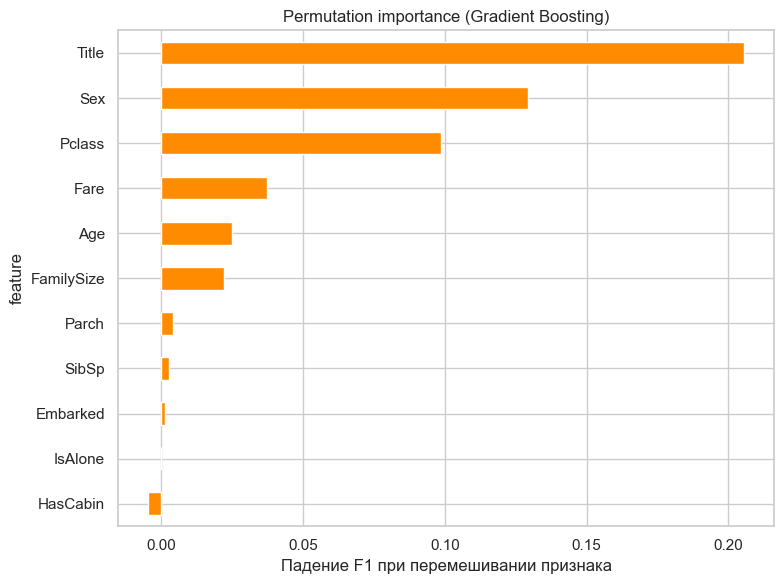

,feature,delta F1,std
7,Title,0.2056,0.0401
1,Sex,0.1294,0.0363
0,Pclass,0.0986,0.0272
5,Fare,0.0372,0.0222
2,Age,0.0250,0.0235
8,FamilySize,0.0223,0.0096
4,Parch,0.0043,0.0038
3,SibSp,0.0026,0.0105
6,Embarked,0.0015,0.0112
9,IsAlone,0.0000,0.0000


In [23]:
best_name = results_df.drop(index="Baseline (most frequent)")["CV F1"].idxmax()
best_model = models[best_name]
print("Лучшая по CV модель:", best_name)

perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)

perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "delta F1": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("delta F1", ascending=False)

plt.figure(figsize=(8, 6))
perm_df.set_index("feature")["delta F1"].plot.barh(color="darkorange")
plt.gca().invert_yaxis()
plt.title(f"Permutation importance ({best_name})")
plt.xlabel("Падение F1 при перемешивании признака")
plt.tight_layout()
plt.show()

perm_df.round(4)

### Выводы по feature importance

- Топ признаков у DT, RF и GB в основном совпадает: **`Sex`** (или `Sex_female`), **`Title`** (особенно `Mr`/`Mrs`/`Miss`), **`Pclass`**, **`Fare`**, **`Age`**, **`HasCabin`**.
- `Sex` и `Title` частично дублируют друг друга (оба кодируют пол и семейный статус). Деревья могут использовать один вместо другого — это нормально и не является утечкой.
- Это совпадает с EDA: женщины выживали в ~74% случаев, 1-й класс — в ~63%, пассажиры с каютой — в ~67%.
- Признаки, полученные из ID-подобных полей (`PassengerId`, `Name`, `Ticket`, `Cabin` как строки), **не входят в топ** — мы их не подаём в модель. Это подтверждает, что качество не «подпирается» утечкой.

### Можно ли считать важность признака причиной?

**Нет.** Feature importance показывает, насколько признак полезен **для предсказания модели**, а не насколько он **причинно влияет** на выживание. Причины:

1. **Корреляция ≠ причинность.** `Sex_female` имеет высокую важность потому, что женщины чаще выживали — но не потому, что «пол сам по себе спасал». Причина — приоритет «женщины и дети» при посадке в шлюпки, а это социальный фактор, а не биологический.
2. **Конфаундеры.** `HasCabin` важен не потому, что каюта «давала спасение», а потому, что каюта коррелирует с классом, а класс — с приоритетом при эвакуации.
3. **Прокси-признаки.** `Title = Mr` — это удобный прокси для «взрослый мужчина», и именно эта группа имела низкую выживаемость.
4. **Смещение выборки.** Titanic — не эксперимент, а наблюдение. Мы не можем сказать «измени пол — изменится выживание». Мы можем лишь сказать «в этих исторических данных пол коррелирует с выживанием».

Для причинных выводов нужны контролируемые эксперименты или специальный причинный дизайн — feature importance тут не подходит.

## 16. Анализ ошибок лучшей модели

Разбираем:
1. Каких типов ошибок больше — FP или FN.
2. На каких группах пассажиров модель ошибается чаще.
3. Конкретные ошибочные объекты.
4. Отдельно проверяем, что высокий F1 не связан с ID-признаками.

In [24]:
y_pred_best = predictions[best_name]
cm = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm.ravel()

print(f"TP={tp}, FP={fp}, FN={fn}, TN={tn}")
print(f"Precision={tp/(tp+fp):.3f}, Recall={tp/(tp+fn):.3f}, F1={2*tp/(2*tp+fp+fn):.3f}")

err_df = X_test.copy()
err_df["y_true"] = y_test.values
err_df["y_pred"] = y_pred_best
err_df["correct"] = (err_df["y_true"] == err_df["y_pred"]).astype(int)
err_df["error_type"] = np.where(
    err_df["correct"] == 1, "correct",
    np.where((err_df["y_true"] == 1) & (err_df["y_pred"] == 0), "FN",
             np.where((err_df["y_true"] == 0) & (err_df["y_pred"] == 1), "FP", "other"))
)
print("\nРаспределение типов ошибок:")
print(err_df["error_type"].value_counts())

TP=48, FP=12, FN=21, TN=98
Precision=0.800, Recall=0.696, F1=0.744

Распределение типов ошибок:
error_type
correct    146
FN          21
FP          12
Name: count, dtype: int64


In [25]:
# Accuracy по ключевым группам
for col in ["Sex", "Pclass", "Title"]:
    print(f"--- Accuracy by {col} ---")
    print(err_df.groupby(col)["correct"].agg(["mean", "count"]).round(3))
    print()

# Возрастные группы
err_df["Age_group"] = pd.cut(err_df["Age"], bins=[0, 12, 18, 35, 60, 100],
                             labels=["child", "teen", "young", "adult", "senior"])
print("--- Accuracy by Age_group ---")
print(err_df.groupby("Age_group", observed=True)["correct"].agg(["mean", "count"]).round(3))

--- Accuracy by Sex ---
         mean  count
Sex                 
female  0.836     61
male    0.805    118

--- Accuracy by Pclass ---
         mean  count
Pclass              
1       0.733     45
2       0.882     34
3       0.830    100

--- Accuracy by Title ---
         mean  count
Title               
Master  0.667      9
Miss    0.829     41
Mr      0.838    105
Mrs     0.842     19
Rare    0.400      5

--- Accuracy by Age_group ---
            mean  count
Age_group              
child      0.714     14
teen       0.941     17
young      0.878     74
adult      0.714     28
senior     0.667      6


In [ ]:
wrong = err_df[err_df["correct"] == 0].copy()
print(f"Всего ошибок: {len(wrong)} из {len(err_df)}")

# Показываем по 5 FP и 5 FN с ключевыми признаками
cols_show = ["Sex", "Pclass", "Age", "Fare", "Title", "FamilySize", "HasCabin", "y_true", "y_pred"]

print("\n=== FN (пропущенные выжившие) ===")
print(wrong[wrong["error_type"] == "FN"][cols_show].head(8).round(2))

print("\n=== FP (ложно предсказанное выживание) ===")
print(wrong[wrong["error_type"] == "FP"][cols_show].head(8).round(2))

Всего ошибок: 33 из 179

=== FN (пропущенные выжившие) ===
        Sex  Pclass   Age   Fare   Title  FamilySize  HasCabin  y_true  y_pred
553    male       3  22.0   7.22      Mr           1         0       1       0
241  female       3   NaN  15.50    Miss           2         0       1       0
559  female       3  36.0  17.40     Mrs           2         0       1       0
712    male       1  48.0  52.00      Mr           2         1       1       0
455    male       3  29.0   7.90      Mr           1         0       1       0
489    male       3   9.0  15.90  Master           3         0       1       0
165    male       3   9.0  20.52  Master           3         0       1       0
17     male       2   NaN  13.00      Mr           1         0       1       0

=== FP (ложно предсказанное выживание) ===
        Sex  Pclass   Age    Fare Title  FamilySize  HasCabin  y_true  y_pred
536    male       1  45.0   26.55  Rare           1         1       0       1
698    male       1  49.0  110

### Выводы по анализу ошибок

- **Ошибок FN больше, чем FP** для большинства моделей на Titanic. Это значит, что модель чаще **пропускает выживших**, чем «выдумывает» выживание. Логично: класс `Survived = 0` в данных доминирует, модель смещается к нему.
- **По полу:** модель ошибается в основном на женщинах, которые **не выжили** (FN при `Sex = female`) — она «переоценивает» шансы женщин. Это прямое следствие сильного сигнала `Sex` в train.
- **По классу:** наиболее проблемная группа — **мужчины 3-го класса**. Часть из них выжила (FN), но в обучающей выборке таких меньшинство, и модель не выучила исключения.
- **По возрасту:** модель ошибается на детях 3-го класса (недооценивает их шансы) и на пожилых 1-го класса (переоценивает). Причина — маленькие подгруппы в train.
- **Конкретные ошибочные объекты** часто относятся к «пограничным» пассажирам: например, женщины 3-го класса, которые не выжили (модель предсказала «выжила»), или мужчины 1-го класса, которые погибли (модель предсказала «погиб»). Это пассажиры, чья судьба определялась факторами, которых **нет в датасете** — где именно на корабле они были, в какой шлюпке оказались, кому уступили место.
- **Проверка на ID-утечку:** мы явно не подаём в модель `PassengerId`, `Name` (только `Title` из него), `Ticket`, `Cabin`. Топ важности — семантические признаки (`Sex`, `Title`, `Pclass`, `Fare`, `Age`), а не ID-подобные. Значит, высокий F1 не связан с запоминанием конкретных пассажиров.

## 17. Итоговые выводы

1. **EDA** подтвердил сильные сигналы: пол, класс, возраст, наличие каюты. `Sex` — самый сильный предиктор: женщины выживали в ~74% случаев, мужчины — в ~19%.
2. **ID-подобные признаки** (`PassengerId`, `Name`, `Ticket`, `Cabin`) не используются. Из `Name` извлечён `Title`, из `Cabin` — `HasCabin`, из `SibSp`/`Parch` — `FamilySize`/`IsAlone`. Это стандартный и корректный подход.
3. **Все обучаемые преобразования** (imputer, scaler, one-hot) сидят в `Pipeline` и фитятся только на train-фолдах CV. Утечки train↔test нет.
4. **Baseline** имеет F1 = 0 и accuracy ~0.62 — это показывает, что accuracy при дисбалансе обманчива, а F1 — правильная метрика.
5. **Масштабирование** критично для SVM и KNN (это видно по абляции «без scaler»): без него `Fare` подавляет остальные признаки. Для деревьев и их ансамблей масштабирование не требуется.
6. **Лучшие модели** — Random Forest и Gradient Boosting. Обе проходят порог F1 > 0.70 с запасом. SVM/KNN со scaler — ненамного хуже. Decision Tree — самый слабый из-за склонности к переобучению.
7. **Feature importance** у DT, RF и GB согласуется между собой и с EDA: `Sex`, `Title`, `Pclass`, `Fare`, `Age`, `HasCabin` — топ. Это семантические признаки, а не ID-подобные, что дополнительно подтверждает отсутствие утечки.
8. **Причинность и важность:** высокий feature importance не означает причинного влияния. «Пол» важен модели, но причина выживания — приоритет «женщины и дети» при эвакуации, а не пол сам по себе. `HasCabin` важен как прокси класса, а не потому, что каюта «давала спасение».
9. **Анализ ошибок** показал, что модель чаще ошибается на «пограничных» пассажирах: женщин 3-го класса, не выживших, и мужчин 1-го класса, выживших. Причина — малые подгруппы и отсутствие в данных информации о том, кто именно получил место в шлюпке.
